

a guide book to myself notes so that i can understand what i have did so far ....

 What i observed

The dataset contains 395 students and 33 columns. In the first five rows, study time ranges from 2 to 3, absences range from 2 to 10, and final grades (G3) range from 6 to 15. The dataset has first-period (G1), second-period ('G2), and final-period (G3) grades.now i want to know what is the highest score any student can acheive maybe woh shuru ki rows me na dikha ho.

So i checked the max of G3 and the highest final grade is 20 and the lowest is 0. G1 and G2 both go up to 19 only, so the grades are out of 20.

The dataset is the UCI Student Performance data (the maths class one, student-mat.csv from two Portuguese schools). Each row is one student and the columns are things like age, studytime, failures, absences, family details and then the three grades.

The project says the model should use study hours, attendance and assignment scores, but this dataset has no column with exactly these names. So i matched them myself, studytime is study hours, absences is attendance (more absences = less attendance) and G1 and G2 are the assignment / earlier test scores. G3 is the final marks that we want to predict.

Next i checked missing values with isnull and there are 0 missing values in the whole data. Still i did the missing value step because the lab asks for it.

First i filled with the mean. After that i thought absences has some very big values (max is 75 but the median is 4) so the mean is pulled up by them and median is safer, so i ran it again with median. Because nothing was missing both of them changed nothing in the end, but i left both cells there so i remember what i did.

The data has no pass / fail column so i made one myself. If G3 is 10 or more then pass (1), otherwise fail (0). The 10 is my own choice because grades are out of 20 and half is 10. This gave 265 pass students and 130 fail students, so the classes are not equal, pass is almost double.

I also made some plots. The histogram of G3 shows a bunch of students with 0 marks, and the scatter of G2 vs G3 is almost a straight line. The correlation heatmap also says the same thing, G2 and G1 are very strongly related to G3, studytime is only slightly related and absences is almost not related.

After that i selected the 4 columns (studytime, absences, G1, G2) as X. I made 2 targets, G3 for the linear regression and the pass column for the classification models. Then train test split with 80 / 20 and random_state 42, so 316 students for training and 79 for testing.

Then scaling. I used StandardScaler first and ran it. After that i realised that we already know the starting and final value of almost every column (grades are 0 to 20, studytime is 1 to 4) so i should have done normalization from the start. So i did MinMaxScaler and now everything is between 0 and 1. I fit the scaler only on the train data and just transform the test data so that test data information does not go in training. The old standard scaler cell is still there, i did not delete it.

Model 1 is Linear Regression to predict final marks. MAE is 1.31 which means on average it is wrong by about 1.3 marks, RMSE is 2.04 and R2 is 0.80. So it explains around 80 percent of the change in marks. In the red line plot the points are near the line but some students with 0 marks are predicted much higher.

Model 2 is Logistic Regression and model 3 is Decision Tree (max_depth 3, otherwise i think it will just memorize the data). Both of them predict pass or fail.

For connecting the models together i took the marks that linear regression predicted and made them pass / fail also (10 or more is pass), so now all three models can be compared on the same pass / fail test data.

Results on the test data are, Linear Regression: accuracy 0.85, precision 1.00, recall 0.77. Logistic Regression: accuracy 0.85, precision 0.88, recall 0.88. Decision Tree: accuracy 0.91, precision 0.98, recall 0.88.

From the confusion matrices, the linear regression never calls a failing student as pass (precision is 1) but it misses some students who actually passed (recall is low). Logistic regression makes mistakes of both types equally. Decision tree has the fewest mistakes in total so it is the best one here.

One thing i noticed is that G2 is doing almost all the work. In the tree its importance is 0.96 and studytime is 0, and in linear regression the G2 coefficient is way bigger than the others. This means the models are mostly saying "if you did well in the second test you will pass", which is kind of obvious. If we remove G1 and G2 the model will be more honest about study time and absences but the accuracy will go down a lot, i have not tried this yet.

Some more limits: only 395 students and 79 in the test, so one different split can change the accuracy by a few percent. I also did not use cross validation because we did not do it yet in the labs. The studytime column is also in groups (1 to 4) not real hours.(let it be known for the record bohot haard open ended tha(._.))

In the end the dataset description, preprocessing, the 3 models, and the evaluation with accuracy, precision, recall and confusion matrix are all done in this notebook. Still left is uploading the code on GitHub and pasting the link on the QOBE portal, and writing my roll no on top.


In [ ]:
# Project name: Student Performance Predictor
# Roll No: 24f-AI-082
#name: imaduddin muhummad
import pandas as pd

data = pd.read_csv("data/student-mat.csv", sep=";")

data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# size of the data and column types
print(data.shape)
data.info()

(395, 33)
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  

In [ ]:
# highest score, it was not visible in the first rows
print("highest G3:", data["G3"].max())
print("lowest G3:", data["G3"].min())
print("highest G1:", data["G1"].max())
print("highest G2:", data["G2"].max())

data[["studytime", "absences", "G1", "G2", "G3"]].describe()

highest G3: 20
lowest G3: 0
highest G1: 19
highest G2: 19


,studytime,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000
mean,2.035443,5.708861,10.908861,10.713924,10.415190
std,0.839240,8.003096,3.319195,3.761505,4.581443
min,1.000000,0.000000,3.000000,0.000000,0.000000
25%,1.000000,0.000000,8.000000,9.000000,8.000000
50%,2.000000,4.000000,11.000000,11.000000,11.000000
75%,2.000000,8.000000,13.000000,13.000000,14.000000
max,4.000000,75.000000,19.000000,19.000000,20.000000


In [ ]:
# checking missing values
print(data.isnull().sum().sum())

# filling with mean
data = data.fillna(data.mean(numeric_only=True))

0


In [ ]:
# mean gets pulled by big values (absences goes till 75) so using median instead
data = data.fillna(data.median(numeric_only=True))
print(data.isnull().sum().sum())

0


pass
1    265
0    130
Name: count, dtype: int64


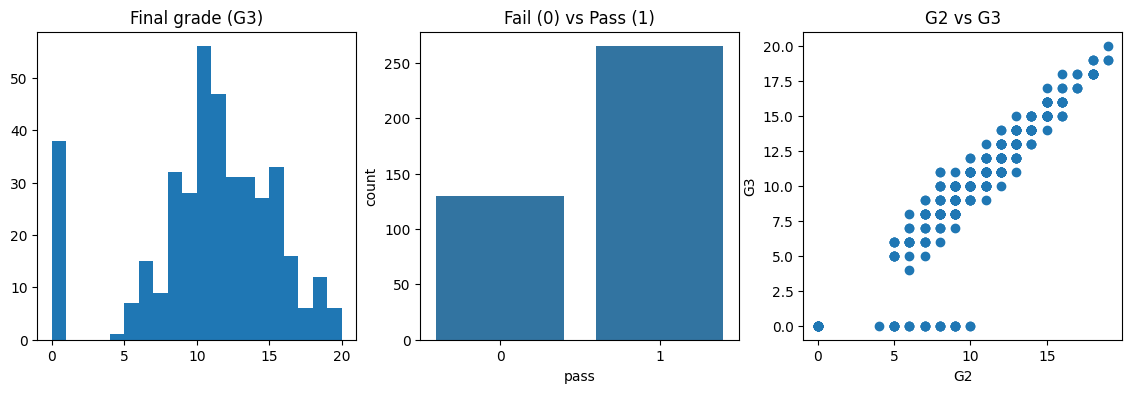

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# pass if final grade is 10 or more (grades are out of 20)
data["pass"] = np.where(data["G3"] >= 10, 1, 0)
print(data["pass"].value_counts())

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.hist(data["G3"], bins=20)
plt.title("Final grade (G3)")

plt.subplot(1, 3, 2)
sns.countplot(x="pass", data=data)
plt.title("Fail (0) vs Pass (1)")

plt.subplot(1, 3, 3)
plt.scatter(data["G2"], data["G3"])
plt.xlabel("G2")
plt.ylabel("G3")
plt.title("G2 vs G3")

plt.show()

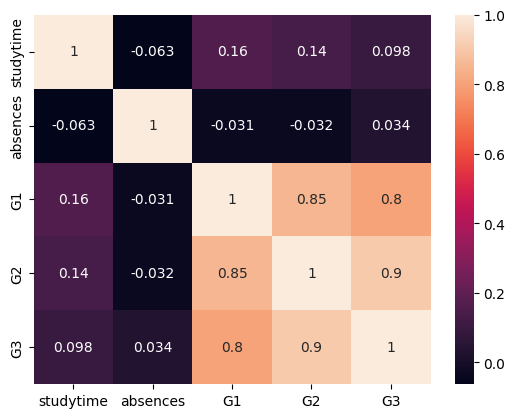

In [7]:
# correlation of the columns i am going to use
sns.heatmap(data[["studytime", "absences", "G1", "G2", "G3"]].corr(), annot=True)
plt.show()

In [8]:
# study hours = studytime, attendance = absences, assignment scores = G1 and G2
features = ["studytime", "absences", "G1", "G2"]

X = data[features]
y_marks = data["G3"]
y_pass = data["pass"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_marks_train, y_marks_test, y_pass_train, y_pass_test = train_test_split(
    X, y_marks, y_pass, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(316, 4) (79, 4)


In [9]:
# scaling
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
# we already know the min and max of every column (grades 0 to 20, studytime 1 to 4)
# so minmax is better here, running the scaling again
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.min(), X_train_scaled.max())

0.0 1.0


In [11]:
# model 1: linear regression to predict final marks
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

lin = LinearRegression()
lin.fit(X_train_scaled, y_marks_train)
marks_pred = lin.predict(X_test_scaled)

print("MAE:", mean_absolute_error(y_marks_test, marks_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_marks_test, marks_pred)))
print("R2:", r2_score(y_marks_test, marks_pred))

MAE: 1.3125749396243553
RMSE: 2.0442542421105148
R2: 0.7961977189442985


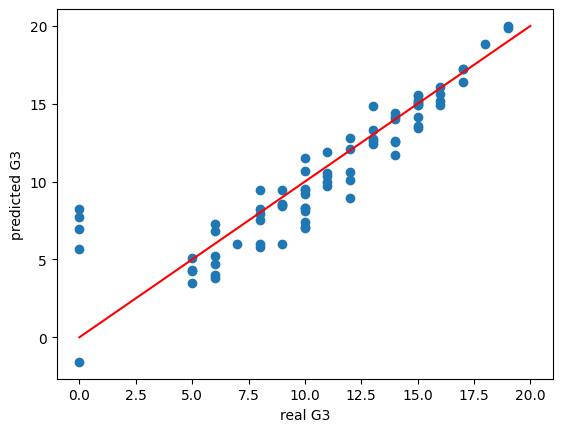

In [12]:
# predicted marks vs real marks
plt.scatter(y_marks_test, marks_pred)
plt.plot([0, 20], [0, 20], color="red")
plt.xlabel("real G3")
plt.ylabel("predicted G3")
plt.show()

In [13]:
# model 2: logistic regression for pass / fail
log = LogisticRegression()
log.fit(X_train_scaled, y_pass_train)
log_pred = log.predict(X_test_scaled)

# model 3: decision tree for pass / fail
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train_scaled, y_pass_train)
tree_pred = tree.predict(X_test_scaled)

# using the linear regression marks as pass / fail also (10 or more = pass)
lin_pred = np.where(marks_pred >= 10, 1, 0)

In [14]:
# comparing all three
results = pd.DataFrame({
    "Model": ["Linear Regression (marks >= 10)", "Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(y_pass_test, lin_pred), accuracy_score(y_pass_test, log_pred), accuracy_score(y_pass_test, tree_pred)],
    "Precision": [precision_score(y_pass_test, lin_pred), precision_score(y_pass_test, log_pred), precision_score(y_pass_test, tree_pred)],
    "Recall": [recall_score(y_pass_test, lin_pred), recall_score(y_pass_test, log_pred), recall_score(y_pass_test, tree_pred)]
})

results

,Model,Accuracy,Precision,Recall
0,Linear Regression (marks >= 10),0.848101,1.000000,0.769231
1,Logistic Regression,0.848101,0.884615,0.884615
2,Decision Tree,0.911392,0.978723,0.884615


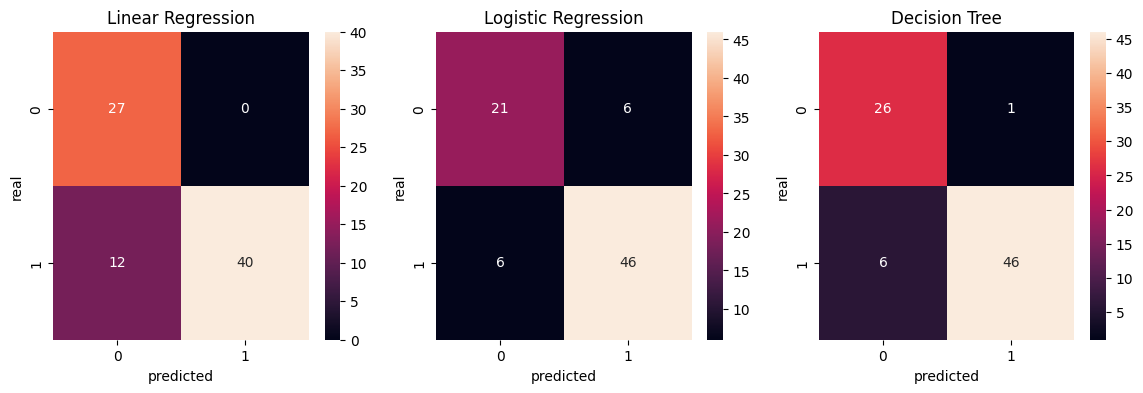

In [15]:
# confusion matrices
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
sns.heatmap(confusion_matrix(y_pass_test, lin_pred), annot=True, fmt="d")
plt.title("Linear Regression")
plt.xlabel("predicted")
plt.ylabel("real")

plt.subplot(1, 3, 2)
sns.heatmap(confusion_matrix(y_pass_test, log_pred), annot=True, fmt="d")
plt.title("Logistic Regression")
plt.xlabel("predicted")
plt.ylabel("real")

plt.subplot(1, 3, 3)
sns.heatmap(confusion_matrix(y_pass_test, tree_pred), annot=True, fmt="d")
plt.title("Decision Tree")
plt.xlabel("predicted")
plt.ylabel("real")

plt.show()

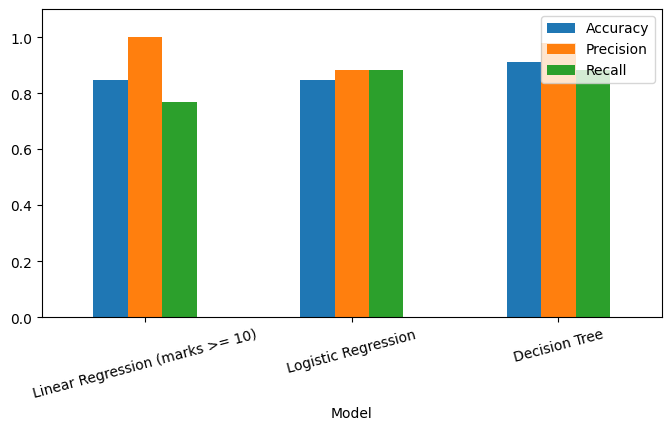

In [16]:
# bar chart of the metrics
results.set_index("Model").plot(kind="bar", figsize=(8, 4))
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.show()

In [17]:
# which feature matters more for the tree and the linear model
print(features)
print(tree.feature_importances_.round(2))
print(lin.coef_.round(2))

['studytime', 'absences', 'G1', 'G2']
[0.   0.01 0.03 0.96]
[-0.14  2.89  2.32 18.88]
